In [17]:
import os
import json
import time
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from google.colab import drive
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

SEED = 123
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [18]:
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import os

search_roots = [
    "/content",
    "/content/drive/MyDrive"
]

dataset_path = None
zip_candidates = []

for base in search_roots:
    if not os.path.exists(base):
        continue

    for root, dirs, files in os.walk(base):
        # Skip hidden/system folders and common irrelevant folders
        dirs[:] = [
            d for d in dirs
            if not d.startswith(".")
            and d not in ["node_modules", "__pycache__"]
        ]

        folder_names = {d.lower() for d in dirs}

        if {"fake", "original"}.issubset(folder_names):
            dataset_path = root
            break

        for filename in files:
            if filename.lower().endswith(".zip"):
                zip_candidates.append(os.path.join(root, filename))

    if dataset_path:
        break

print("Dataset folder found:", dataset_path)
print("ZIP files found:", zip_candidates[:20])

Dataset folder found: None
ZIP files found: ['/content/KYC DATASET.zip', '/content/drive/MyDrive/KYC DATASET.zip', '/content/drive/MyDrive/Saved from Chrome/Lab6 _IMD_.zip', '/content/drive/MyDrive/Saved from Chrome/Lab4_IMD_.zip', '/content/drive/MyDrive/Saved from Chrome/Intelligent model design with AI ASSIGNMENT 5.zip', '/content/drive/MyDrive/Saved from Chrome/S24BCAU0184 LAB 7.zip', '/content/drive/MyDrive/Saved from Chrome/S24BCAU0184 LAB 8.zip', '/content/drive/MyDrive/Saved from Chrome/Lab assignment 9 intelligent model.zip', '/content/drive/MyDrive/Saved from Chrome/lab assignment 10, 0184, 0156.zip', '/content/drive/MyDrive/KYC DATASET.zip', '/content/drive/MyDrive/Saved from Chrome/Lab6 _IMD_.zip', '/content/drive/MyDrive/Saved from Chrome/Lab4_IMD_.zip', '/content/drive/MyDrive/Saved from Chrome/Intelligent model design with AI ASSIGNMENT 5.zip', '/content/drive/MyDrive/Saved from Chrome/S24BCAU0184 LAB 7.zip', '/content/drive/MyDrive/Saved from Chrome/S24BCAU0184 LAB 8.zi

In [23]:
import os
import zipfile

zip_path = "/content/KYC DATASET.zip"

print("File exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("File size:", os.path.getsize(zip_path), "bytes")
    print("Is valid ZIP:", zipfile.is_zipfile(zip_path))

File exists: True
File size: 110037035 bytes
Is valid ZIP: True


In [24]:
import os
import zipfile

if dataset_path is None:
    if not zip_candidates:
        raise FileNotFoundError(
            "No dataset folder or ZIP was found. "
            "Check the Colab Files panel and Google Drive."
        )

    # Prefer a ZIP whose filename contains KYC
    kyc_zips = [
        p for p in zip_candidates
        if "kyc" in os.path.basename(p).lower()
    ]

    zip_path = kyc_zips[0] if kyc_zips else zip_candidates[0]
    extract_dir = "/content/kyc_data"

    os.makedirs(extract_dir, exist_ok=True)

    print("Extracting:", zip_path)

    with zipfile.ZipFile(zip_path, "r") as z:
        bad_file = z.testzip()

        if bad_file:
            raise RuntimeError(f"Corrupted ZIP member: {bad_file}")

        z.extractall(extract_dir)

    # Search extracted folders
    for root, dirs, files in os.walk(extract_dir):
        folder_names = {d.lower() for d in dirs}

        if {"fake", "original"}.issubset(folder_names):
            dataset_path = root
            break

if dataset_path is None:
    raise FileNotFoundError(
        "The ZIP was extracted, but no parent folder containing "
        "both Fake and Original was found. Inspect the ZIP structure."
    )

print("Using dataset:", dataset_path)
print("Folders:", os.listdir(dataset_path))

Extracting: /content/KYC DATASET.zip
Using dataset: /content/kyc_data/KYC DATASET
Folders: ['Original', 'Fake']


In [25]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 15

train_raw = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

holdout_raw = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_raw.class_names

print("Class names:", class_names)
print("Class mapping:", {name: i for i, name in enumerate(class_names)})

if len(class_names) != 2:
    raise ValueError("Exactly two class folders are required.")

holdout_batches = tf.data.experimental.cardinality(
    holdout_raw
).numpy()

if holdout_batches < 2:
    raise ValueError(
        "Too few holdout batches. Reduce BATCH_SIZE or add more images."
    )

val_batches = holdout_batches // 2

val_raw = holdout_raw.take(val_batches)
test_raw = holdout_raw.skip(val_batches)

print("Training batches:", tf.data.experimental.cardinality(train_raw).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_raw).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_raw).numpy())

Found 200 files belonging to 2 classes.
Using 140 files for training.
Found 200 files belonging to 2 classes.
Using 60 files for validation.
Class names: ['Fake', 'Original']
Class mapping: {'Fake': 0, 'Original': 1}
Training batches: 9
Validation batches: 2
Test batches: 2


In [26]:
AUTOTUNE = tf.data.AUTOTUNE

def prepare_images(images, labels):
    images = preprocess_input(tf.cast(images, tf.float32))
    return images, labels

train_ds = train_raw.map(
    prepare_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = val_raw.map(
    prepare_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_raw.map(
    prepare_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Image preprocessing completed.")

Image preprocessing completed.


In [27]:
base_model = VGG19(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained convolutional layers
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 7, 7, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,090,177 (76.64 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [28]:
output_dir = "/content/drive/MyDrive/KYC_Phase2"
os.makedirs(output_dir, exist_ok=True)

model_path = os.path.join(output_dir, "kyc_vgg19_best.keras")

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

training_time = time.time() - start_time

print(f"Training time: {training_time / 60:.2f} minutes")
print("Best model saved at:", model_path)

Epoch 1/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy: 0.4524 - loss: 2.9314
Epoch 1: val_loss improved from None to 2.28745, saving model to /content/drive/MyDrive/KYC_Phase2/kyc_vgg19_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/KYC_Phase2/kyc_vgg19_best.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 15s 741ms/step - accuracy: 0.4286 - loss: 2.6071 - val_accuracy: 0.0312 - val_loss: 2.2874
Epoch 2/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.5146 - loss: 1.8842
Epoch 2: val_loss did not improve from 2.28745
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 542ms/step - accuracy: 0.4857 - loss: 1.9779 - val_accuracy: 0.0000e+00 - val_loss: 2.7054
Epoch 3/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.5030 - loss: 1.6237
Epoch 3: val_loss improved from 2.28745 to 0.10737, saving model to /content/drive/MyDrive/KYC_Phase2/kyc_vgg19_best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/KYC_Phase2/kyc_vgg19_best.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 368ms/step - ac

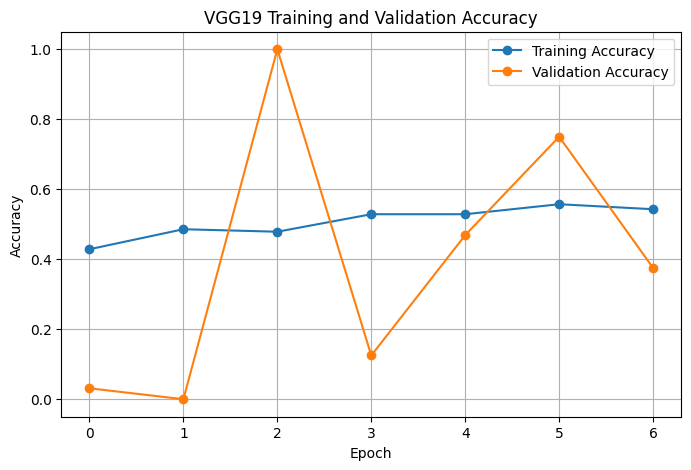

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("VGG19 Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(output_dir, "vgg19_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

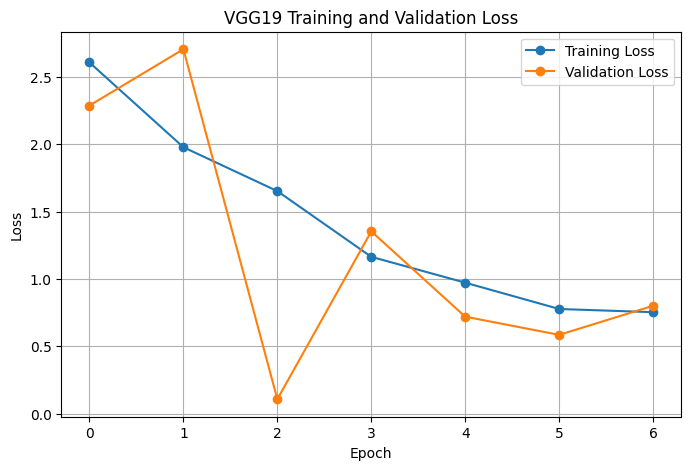

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG19 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(output_dir, "vgg19_loss.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
model = tf.keras.models.load_model(model_path)

y_true = []
y_prob = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0).ravel()
    y_prob.extend(probabilities)
    y_true.extend(labels.numpy().ravel().astype(int))

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

fake_index = class_names.index("Fake") if "Fake" in class_names else None

if fake_index is None:
    raise ValueError(
        f"'Fake' class not found. Actual classes: {class_names}"
    )

# Keras sigmoid predicts class index 1 at probability >= 0.5.
# Convert predictions to a fake-positive convention for metrics.
y_true_fake = (y_true == fake_index).astype(int)
y_pred_fake = (y_pred == fake_index).astype(int)

accuracy = accuracy_score(y_true_fake, y_pred_fake)
precision = precision_score(y_true_fake, y_pred_fake, zero_division=0)
recall = recall_score(y_true_fake, y_pred_fake, zero_division=0)
f1 = f1_score(y_true_fake, y_pred_fake, zero_division=0)

print("========== VGG19 TEST RESULTS ==========")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Fake precision: {precision:.4f}")
print(f"Fake recall:    {recall:.4f}")
print(f"Fake F1-score:  {f1:.4f}")
print(f"Training time: {training_time / 60:.2f} minutes")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

========== VGG19 TEST RESULTS ==========
Accuracy:  1.0000
Fake precision: 0.0000
Fake recall:    0.0000
Fake F1-score:  0.0000
Training time: 0.65 minutes

Classification report:
              precision    recall  f1-score   support

        Fake       0.00      0.00      0.00         0
    Original       1.00      1.00      1.00        28

    accuracy                           1.00        28
   macro avg       0.50      0.50      0.50        28
weighted avg       1.00      1.00      1.00        28



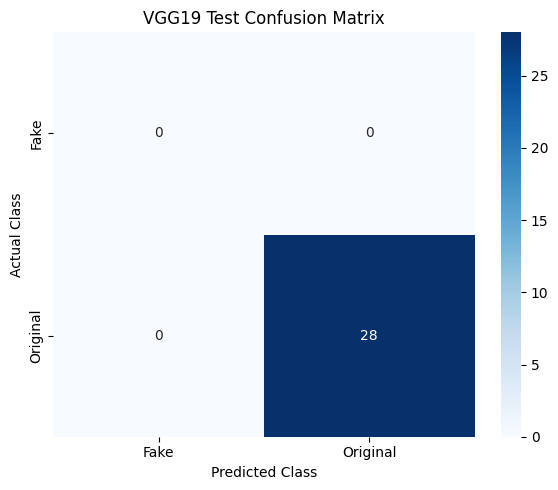

In [32]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("VGG19 Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "vgg19_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
results = {
    "model": "VGG19",
    "classes": class_names,
    "epochs_completed": len(history.history["loss"]),
    "test_accuracy": float(accuracy),
    "fake_precision": float(precision),
    "fake_recall": float(recall),
    "fake_f1_score": float(f1),
    "training_time_minutes": float(training_time / 60),
    "confusion_matrix": cm.tolist()
}

results_path = os.path.join(output_dir, "vgg19_results.json")

with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print("VGG19 results saved in:", output_dir)
print("Results file:", results_path)

VGG19 results saved in: /content/drive/MyDrive/KYC_Phase2
Results file: /content/drive/MyDrive/KYC_Phase2/vgg19_results.json
